# East Africa Agri Regulation Signals 2026

WTO notifications, Kenyan bills and EU alerts on farm goods, 2026. A free sample from [NuaSense](https://agriculture-data.com), East African agricultural data; also on [Hugging Face](https://huggingface.co/datasets/nuasense/east-africa-agri-regulation-signals) (CC BY-NC 4.0).

In [1]:
import glob, os
import pandas as pd
import matplotlib.pyplot as plt

plt.rcParams.update({"figure.figsize": (9, 4.5), "axes.spines.top": False, "axes.spines.right": False,
                     "axes.grid": True, "grid.color": "#ecebe7", "axes.axisbelow": True, "font.size": 10})
BLUE, ORANGE, AQUA = "#2a78d6", "#eb6834", "#1baf7a"

def load(name, hf_url):
    # On Kaggle the CSV sits under /kaggle/input; in Colab or on your machine the same table
    # is read straight from Hugging Face.
    hits = glob.glob(f"/kaggle/input/**/{name}", recursive=True) + glob.glob(f"**/{name}", recursive=True)
    return pd.read_csv(hits[0]) if hits else pd.read_parquet(hf_url)

df = load("east_africa_agri_regulation_signals_2026.csv", "https://huggingface.co/datasets/nuasense/east-africa-agri-regulation-signals/resolve/main/data/signals/signals.parquet")
print(f"{len(df):,} rows")
df.head()

769 rows


,date,country,jurisdiction,channel,regulation_type,instrument_type,status,commodity,title,summary,obligation,doc_ref,source_url,comment_deadline,effective_date,value,value_unit,extraction_confidence
0,2026-02-01,KE,KE,bills,compliance_regime,bill,proposed,sugar,The Sugar Bill (National Assembly No. 34) 2022,Would regulate Kenya's sugar sector; contents ...,NaN,KE-bill-senate-238,https://mzalendo.com/legislative-trends/bills/...,NaN,NaN,NaN,NaN,0.4
1,2026-02-01,KE,KE,bills,land_water,bill,lapsed,unknown,The Land Laws (Amendment) (No.2) Bill 2023,Would amend Kenya's land laws; contents not ye...,NaN,KE-bill-na-273,https://mzalendo.com/legislative-trends/bills/...,NaN,NaN,NaN,NaN,0.4
2,2026-07-02,KE,KE,bills,institutional,bill,proposed,unknown,"Nuts and Oil Crops Development Bill, No.47 of ...",Would establish a legal framework for the deve...,NaN,KE-bill-na-602,https://mzalendo.com/legislative-trends/bills/...,NaN,NaN,NaN,NaN,0.5
3,2026-07-03,KE,KE,bills,compliance_regime,bill,adopted,coffee,The Coffee Bill (Senate Bill No. 10 of 2023),Would change Kenya's legal framework for the c...,NaN,KE-bill-na-550,https://mzalendo.com/legislative-trends/bills/...,NaN,NaN,NaN,NaN,0.5
4,2026-07-03,KE,KE,bills,compliance_regime,bill,proposed,coffee,"Kenya Coffee Bill, 2023",Would regulate Kenya's coffee sector; the full...,NaN,KE-bill-senate-416,https://mzalendo.com/legislative-trends/bills/...,NaN,NaN,NaN,NaN,0.4


## Signals per month and channel

In [2]:
df["month"] = df.date.str[:7]
pd.crosstab(df.month, df.channel)

channel,bills,eping,lii,rasff
month,,,,
2026-02,2,0,0,0
2026-07,57,0,1,0
2026-08,11,109,0,5
2026-09,3,246,0,1
2026-10,0,168,0,2
2026-11,0,164,0,0


## Still open for comment

Notifications whose comment deadline has not passed: the window in which an exporting country can object.

In [3]:
today = pd.Timestamp.today().normalize()
open_ = df[pd.to_datetime(df.comment_deadline, errors="coerce") >= today]
open_.drop_duplicates("doc_ref").sort_values("comment_deadline")[["comment_deadline", "jurisdiction", "regulation_type", "commodity", "title", "doc_ref"]].head(20)

,comment_deadline,jurisdiction,regulation_type,commodity,title,doc_ref
368,2026-11-19,KE,standard,unknown,"Draft Kenya Standard on food safety, quality a...",G/TBT/N/KEN/2113
369,2026-11-19,KE,standard,unknown,Kenya draft standard on cereals and pulses cod...,G/TBT/N/KEN/2112
411,2026-11-24,TZ,standard,fish,Tanzania draft standard for fish nuggets (DARS...,G/SPS/N/TZA/550
414,2026-11-27,TZ,standard,fish,Draft Tanzania standard for fish nuggets notif...,G/TBT/N/TZA/1662
457,2026-11-30,WTO,residue_limit,sugar,US establishes residue tolerance for sodium sa...,G/SPS/N/USA/3598
443,2026-12-01,EU,registration_licensing,animal_feed,EU draft regulation would reauthorise two anis...,G/SPS/N/EU/975
221,2026-12-04,WTO,standard,unknown,Proposed Amendments to the Sweeteners in Food ...,G/SPS/N/HKG/51
507,2026-12-04,TZ,standard,unknown,Draft Tanzania Standard for edible olive oil a...,G/SPS/N/TZA/552
508,2026-12-04,TZ,standard,unknown,"Tanzania Draft Standard AFDC 4 (4549) DTZS, Aq...",G/SPS/N/TZA/551
509,2026-12-04,TZ,standard,unknown,Draft Tanzania Standard: Edible olive oil and ...,G/TBT/N/TZA/1663


## Pesticide residue limits

Who is changing maximum residue limits, the rules that decide whether a consignment is rejected at the border.

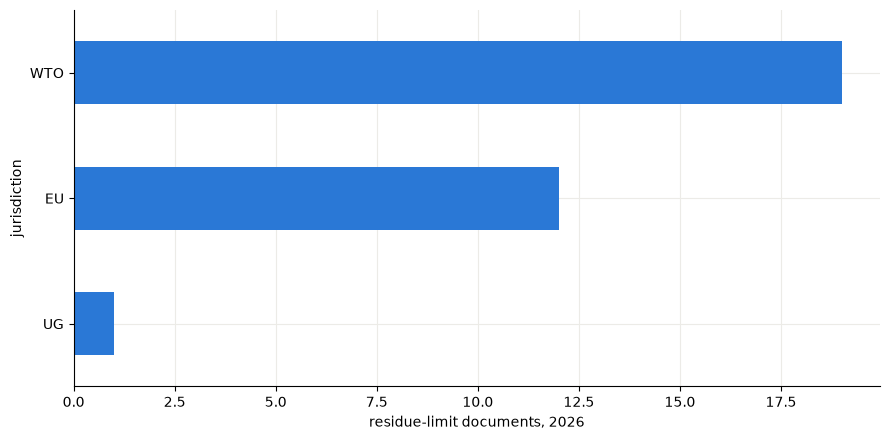

In [4]:
mrl = df[df.regulation_type == "residue_limit"].drop_duplicates("doc_ref")
ax = mrl.jurisdiction.value_counts().plot.barh(color=BLUE)
ax.set_xlabel("residue-limit documents, 2026"); ax.invert_yaxis()
plt.tight_layout(); plt.show()

## The full data

The NuaSense API serves the weekly updates with the supporting passage behind each signal, and an export residue check that sets EU limits beside Kenya's pesticide register.

```
pip install nuasense
```

A key with a free monthly allowance comes from [platform.nuasense.com](https://platform.nuasense.com/start). On Kaggle, store it as a secret named `NUASENSE_API_KEY` (Add-ons → Secrets). Fields and filters: [agriculture-data.com](https://agriculture-data.com/datasets/regulatory-and-legal/regulatory/).

In [5]:
# Runs only when a NuaSense key is available (Kaggle secret NUASENSE_API_KEY or an environment variable).
try:
    from kaggle_secrets import UserSecretsClient
    os.environ.setdefault("NUASENSE_API_KEY", UserSecretsClient().get_secret("NUASENSE_API_KEY"))
except Exception:
    pass

if os.environ.get("NUASENSE_API_KEY"):
    import subprocess, sys
    subprocess.run([sys.executable, "-m", "pip", "install", "-q", "nuasense"], check=False)
    import nuasense
    ns = nuasense.Client()
    rows = ns.rows("/market/regulatory", start="-30d", limit=100, country="ke")
    display(pd.DataFrame(rows).head())
else:
    print("No NUASENSE_API_KEY set: add it as a Kaggle secret (Add-ons -> Secrets) to read the full series.")

No NUASENSE_API_KEY set: add it as a Kaggle secret (Add-ons -> Secrets) to read the full series.
